In [1]:
## import basic library

import torch

print(torch.__version__)
print(torch.cuda.is_available())

import laspy
import numpy as np
import os
from open3d.ml.datasets import SemanticKITTI
import open3d.ml as _ml3d
import open3d.ml.torch as ml3d 
import matplotlib.pyplot as plt

2.2.2+cu121
False
Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [5]:
# convert las pointcloud file to semantikitti dataset 

las = laspy.read("../data/processed_pipeline_corridor/40kmh_pipeline_corridor.las")
output_dir = "dataset/dataset/sequences/40_pipeline_corridor/velodyne"
labels_dir = "dataset/dataset/sequences/40_pipeline_corridor/labels"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(labels_dir, exist_ok=True)


x = np.array(las.x)
y = np.array(las.y)
z = np.array(las.z)

if hasattr(las, "intensity"):
    intensity = np.array(las.intensity, dtype=np.float32)
    if intensity.max() > 0:
        intensity = intensity / intensity.max()
else:
    intensity = np.zeros(len(x), dtype=np.float32)

# Re-center (SemanticKITTI scans are local to the sensor, not global UTM coords)
points = np.vstack((x, y, z)).T.astype(np.float32)
centroid = points.mean(axis=0)
points_centered = points - centroid

# Combine into [x, y, z, intensity] — this is the exact SemanticKITTI .bin format
scan = np.hstack((points_centered, intensity.reshape(-1, 1))).astype(np.float32)

# Save as binary .bin file (SemanticKITTI naming convention: 6-digit frame number)
bin_path = os.path.join(output_dir, "000000.bin")
scan.tofile(bin_path)
print(f"Saved {bin_path} — {len(scan)} points")

# Dummy label file (all zeros = "unlabeled") — only needed if the loader requires the file to exist
dummy_labels = np.zeros(len(scan), dtype=np.uint32)
label_path = os.path.join(labels_dir, "000000.label")
dummy_labels.tofile(label_path)
print(f"Saved {label_path}")

Saved dataset/dataset/sequences/40_pipeline_corridor/velodyne/000000.bin — 7307498 points
Saved dataset/dataset/sequences/40_pipeline_corridor/labels/000000.label


In [6]:
# check convertion
dataset_name = '40_pipeline_corridor'

dataset = SemanticKITTI(dataset_path="dataset/", use_cache=False)

dataset.cfg.test_split = [dataset_name] 

# Get the test/inference split
test_split = dataset.get_split("test")

# Pull one frame
data = test_split.get_data(0)
print(data.keys())
print(data['point'].shape)

dict_keys(['point', 'feat', 'label'])
(7307498, 3)


In [7]:
 # requires PyTorch installed: pip install torch

# This loads the model architecture config
cfg_file = 'configs/randlanet_semantickitti.yml'
cfg = _ml3d.utils.Config.load_from_file(cfg_file)

model = ml3d.models.RandLANet(**cfg.model)
pipeline = ml3d.pipelines.SemanticSegmentation(model, **cfg.pipeline)

In [8]:
model.eval()

RandLANet(
  (fc0): Linear(in_features=3, out_features=8, bias=True)
  (bn0): BatchNorm2d(8, eps=1e-06, momentum=0.01, affine=True, track_running_stats=True)
  (encoder): ModuleList(
    (0): LocalFeatureAggregation(
      (mlp1): SharedMLP(
        (conv): Conv2d(8, 8, kernel_size=(1, 1), stride=(1, 1))
        (batch_norm): BatchNorm2d(8, eps=1e-06, momentum=0.01, affine=True, track_running_stats=True)
        (activation_fn): LeakyReLU(negative_slope=0.2)
      )
      (lse1): LocalSpatialEncoding(
        (mlp): SharedMLP(
          (conv): Conv2d(10, 8, kernel_size=(1, 1), stride=(1, 1))
          (batch_norm): BatchNorm2d(8, eps=1e-06, momentum=0.01, affine=True, track_running_stats=True)
          (activation_fn): LeakyReLU(negative_slope=0.2)
        )
      )
      (pool1): AttentivePooling(
        (score_fn): Sequential(
          (0): Linear(in_features=16, out_features=16, bias=True)
          (1): Softmax(dim=-2)
        )
        (mlp): SharedMLP(
          (conv): Conv2

In [9]:
print("Model expects in_channels:", model.cfg.in_channels)
print("data['point'] shape:", data['point'].shape)
print("data['feat'] shape:", data['feat'].shape if data['feat'] is not None else None)

Model expects in_channels: 3
data['point'] shape: (7307498, 3)
data['feat'] shape: (7307498, 1)


In [10]:
# run pretained model for evalution

data = test_split.get_data(0)
data['feat'] = None
print("feat is:", data['feat'])   # sanity check right before running

results = pipeline.run_inference(data)
predicted_labels = results['predict_labels']
print("Unique predicted classes:", np.unique(predicted_labels))


feat is: None


test 0/1: 100%|██████████| 176703/176703 [01:06<00:00, 1902.15it/s]lidar_env/lib/python3.11/site-packages/open3d/_ml3d/torch/modules/metrics/semseg_metric.py:54: RuntimeWarning: Mean of empty slice
  accs.append(np.nanmean(accs))
lidar_env/lib/python3.11/site-packages/open3d/_ml3d/torch/modules/metrics/semseg_metric.py:87: RuntimeWarning: Mean of empty slice
  ious.append(np.nanmean(ious))


Unique predicted classes: [13 14 16]


In [11]:
print(predicted_labels)


[16 16 16 ... 14 14 14]


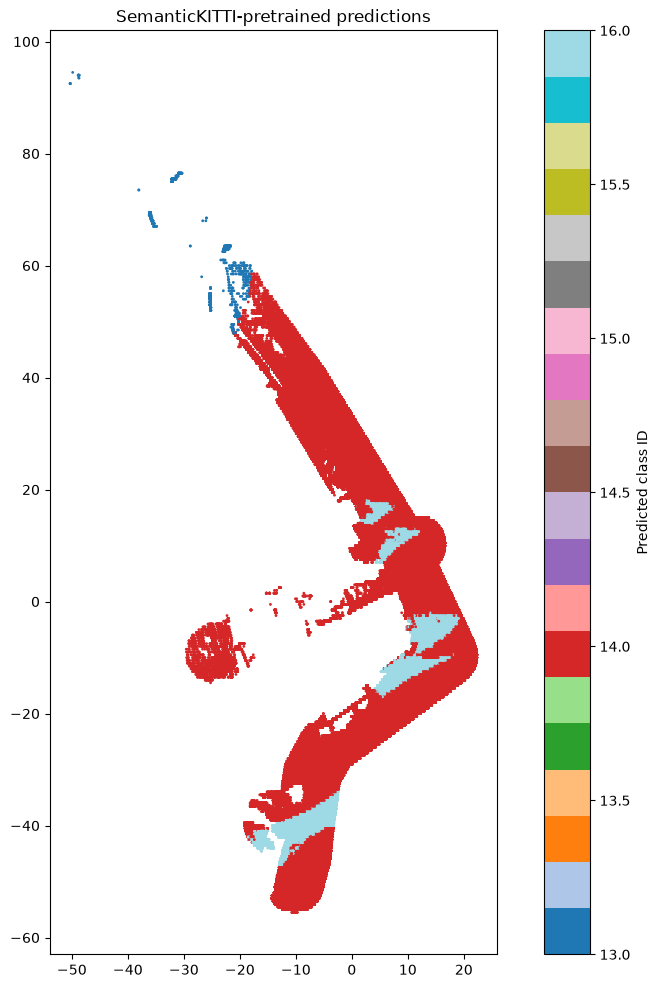

In [12]:
# plot model results

plt.figure(figsize=(12, 12))
scatter = plt.scatter( data['point'][:, 0],  data['point'][:, 1],
                       c=predicted_labels, s=1, cmap='tab20')
plt.colorbar(scatter, label="Predicted class ID")
plt.gca().set_aspect('equal')
plt.title("SemanticKITTI-pretrained predictions")
plt.show()

In [13]:
# Check number of available lables 

label_map = dataset.label_to_names
print(label_map)

{0: 'unlabeled', 1: 'car', 2: 'bicycle', 3: 'motorcycle', 4: 'truck', 5: 'other-vehicle', 6: 'person', 7: 'bicyclist', 8: 'motorcyclist', 9: 'road', 10: 'parking', 11: 'sidewalk', 12: 'other-ground', 13: 'building', 14: 'fence', 15: 'vegetation', 16: 'trunk', 17: 'terrain', 18: 'pole', 19: 'traffic-sign'}


In [14]:
# Count number of unique labes and points

unique_ids, counts = np.unique(predicted_labels, return_counts=True)
label_map = dataset.label_to_names  # {id: class_name}


for uid, cnt in zip(unique_ids, counts):
    print(f"{uid:2d}  {label_map.get(uid, 'unknown'):15s}  {cnt} points")

13  building         3727 points
14  fence            6420939 points
16  trunk            882832 points
